# When MNIST Accuracy Is Not Enough

In this project, we compare a **MLP** with a **CNN** for handwritten digit classification. We use the MNIST dataset to train both models and compare their performance.

Reaching a high accuracy using MNIST is easy, as its digits are centered, the backgrounds are clean, and the test set is very similar to the training data. That is why we not only try to observe which model performs better under normal circumstances, but also see its accuracy when the input changes slightly.

- How well do both models perform on clean MNIST?
- Which digits do they confuse, and do they make the same mistakes?
- How much accuracy do they lose when digits are partly modified?
- When a model is wrong, is it also overconfident?

## 1. Imports and reproducibility

We set a random seed so that the parts of the experiment that involve randomness are reproducible.

In [44]:
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms
from torchvision.transforms import functional as TF
from torchvision.transforms import InterpolationMode

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

SEED = 42
BATCH_SIZE = 128

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

## 2. Load MNIST

MNIST already provides a training set with 60,000 images and a test set with 10,000 images, so we use those two sets directly.

In [45]:
mean = (0.1307,)
std = (0.3081,)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)])

train_data = datasets.MNIST(root="./data", train=True, download=True, transform=transform)

test_data = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)

test_loader = DataLoader(test_data, batch_size=BATCH_SIZE)

print(f"Train: {len(train_data):,}")
print(f"Test: {len(test_data):,}")

Train: 60,000
Test: 10,000


## 3. First look at the data

Before training the models, we look at a few examples and see how many images we have for each digit.

This helps us understand what the dataset looks like, and whether the classes are balanced. This is important because class imbalance can affect how we train and evaluate a model. If some digits appeared much more often than others, accuracy alone could be misleading, and we might need to use techniques such as resampling or more robust metrics like precision and recall.

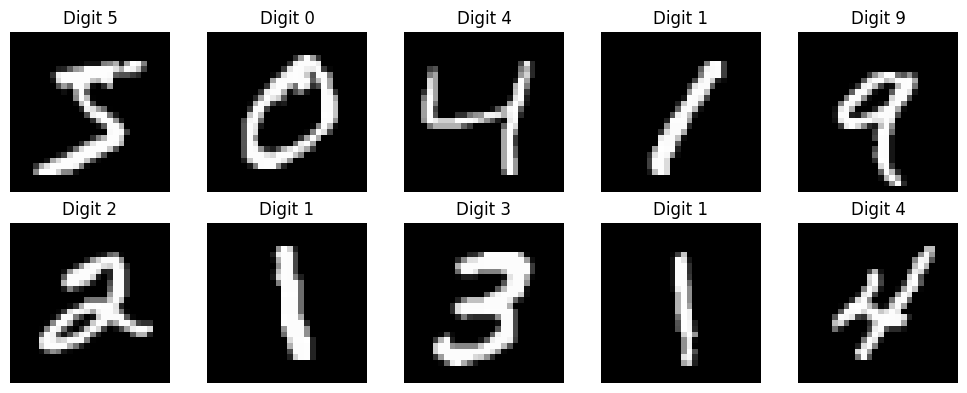

In [46]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for i, ax in enumerate(axes.flat):
    image, label = train_data[i]
    image = image * std[0] + mean[0]  # undo normalization for plotting

    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Digit {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

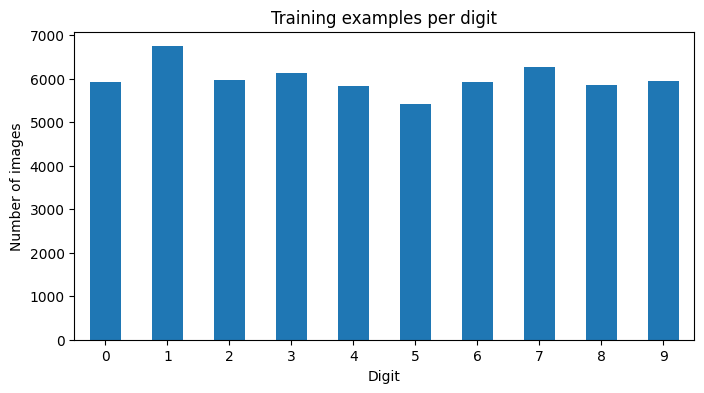

In [47]:
class_counts = pd.Series(train_data.targets.numpy()).value_counts().sort_index()

class_counts.plot(kind="bar", figsize=(8, 4))
plt.title("Training examples per digit")
plt.xlabel("Digit")
plt.ylabel("Number of images")
plt.xticks(rotation=0)
plt.show()

In this case, the classes are fairly balanced, so the overall accuracy is a reasonable metric to use.

## 4. Two models

We compare the models that process the 28×28 images differently.

- The **MLP** flattens the image into a vector of 784 pixel values, so the 2-dimensional structure of the image is lost, and the model processes all pixels as a single sequence of numbers.
- The **CNN** keeps the 2-dimensional structure of the image and applies small filters across regions, allowing the model to detect visual patterns.

In both models, the final layer has 10 outputs, one for each digit (0 to 9).

Both architectures are simple, as the purpose of this project is not to build the strongest possible model, but to compare their behavior when the input changes.

In [48]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10))

    def forward(self, x):
        return self.layers(x)


class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 64),
            nn.ReLU(),
            nn.Linear(64, 10))

    def forward(self, x):
        return self.layers(x)


models = {
    "MLP": MLP(),
    "CNN": CNN()}

for name, model in models.items():
    parameters = sum(p.numel() for p in model.parameters())
    print(f"{name}: {parameters} parameters")

MLP: 109386 parameters
CNN: 105866 parameters


## 5. Training

We train both models under the same conditions: the same batch size, optimizer, learning rate, and number of epochs.

In [49]:
def evaluate_accuracy(model, loader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            predictions = model(images).argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += len(labels)

    return correct / total


def train_model(model, loader, epochs=5):
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    loss_fn = nn.CrossEntropyLoss()
    history = []

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0

        for images, labels in loader:
            optimizer.zero_grad()

            predictions = model(images)
            loss = loss_fn(predictions, labels)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(labels)

        train_loss = total_loss / len(loader.dataset)

        history.append({
            "epoch": epoch,
            "train_loss": train_loss})

        print(
            f"Epoch {epoch}: "
            f"training loss = {train_loss:.4f}")

    return pd.DataFrame(history)

In [50]:
histories = {}

for name, model in models.items():
    print(f"\nTraining {name}")
    histories[name] = train_model(model, train_loader, epochs=5)


Training MLP
Epoch 1: training loss = 0.3194
Epoch 2: training loss = 0.1277
Epoch 3: training loss = 0.0889
Epoch 4: training loss = 0.0654
Epoch 5: training loss = 0.0536

Training CNN
Epoch 1: training loss = 0.2249
Epoch 2: training loss = 0.0627
Epoch 3: training loss = 0.0451
Epoch 4: training loss = 0.0363
Epoch 5: training loss = 0.0281


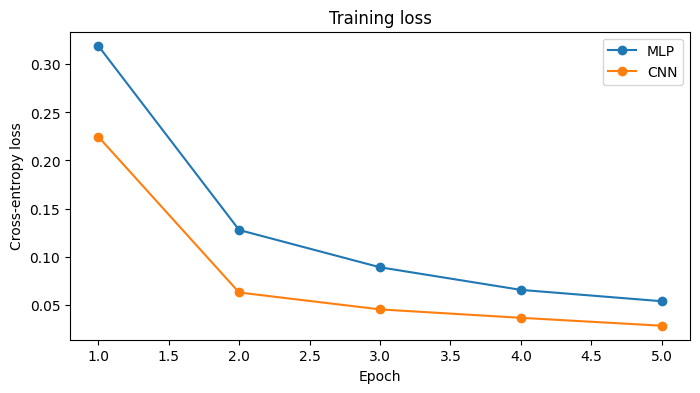

In [51]:
plt.figure(figsize=(8, 4))

for name, history in histories.items():
    plt.plot(
        history["epoch"],
        history["train_loss"],
        marker="o",
        label=name)

plt.title("Training loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.legend()
plt.show()

Looking at the training curves, we can see that the cross-entropy loss is higher for the MLP than for the CNN throughout training. This suggests that the CNN fits the training data better.

For both models, the largest decrease in loss happens during the first two epochs. After that, the loss continues to decrease, but more gradually. This suggests that both models learn most of the main patterns in the data early in the training process, and then refine what they have already learned.

## 6. Test performance

Once both models have finished training, we evaluate them on the test set.

We store the true labels, predicted labels and probabilities because we will reuse them later on.

In [52]:
def predict(model, loader):
    model.eval()
    labels_list = []
    predictions_list = []
    probabilities_list = []

    with torch.no_grad():
        for images, labels in loader:
            logits = model(images)
            probabilities = torch.softmax(logits, dim=1)

            labels_list.append(labels)
            predictions_list.append(probabilities.argmax(dim=1))
            probabilities_list.append(probabilities)

    return (
        torch.cat(labels_list),
        torch.cat(predictions_list),
        torch.cat(probabilities_list))


clean_predictions = {}
clean_rows = []

for name, model in models.items():
    y_true, y_pred, probabilities = predict(model, test_loader)
    accuracy = (y_true == y_pred).float().mean().item()

    clean_predictions[name] = (y_true, y_pred, probabilities)
    clean_rows.append({"Model": name, "Accuracy": accuracy})

clean_results = pd.DataFrame(clean_rows).set_index("Model")
clean_results

,Accuracy
Model,
MLP,0.9748
CNN,0.9874


As expected, the CNN achieves a higher accuracy than the MLP. Both models have an accuracy above 0.95, which means that they classify correctly most of the images.

However, this high accuracy does not tell us how the models will behave when the input images are slightly different from the ones seen during training, so we also test their performance under several modifications.

## 7. Which digits are difficult?

We calculate the accuracy separately for each digit to identify which digits are more difficult to classify, and compare how each model performs across the different classes.

In [53]:
rows = []

for name, (y_true, y_pred, _) in clean_predictions.items():
    for digit in range(10):
        mask = y_true == digit
        digit_accuracy = (y_pred[mask] == y_true[mask]).float().mean().item()
        rows.append({"Model": name, "Digit": digit, "Accuracy": digit_accuracy})

per_digit = pd.DataFrame(rows)
per_digit.pivot(index="Digit", columns="Model", values="Accuracy")

Model,CNN,MLP
Digit,,
0,0.997959,0.991837
1,0.991189,0.988546
2,0.978682,0.990310
3,0.992079,0.977228
4,0.995927,0.962322
5,0.980942,0.976457
6,0.982255,0.977035
7,0.987354,0.967899
8,0.990760,0.975359


CNN outperforms MLP for all digits except digit 2. This shows that the CNN does not perform better for every single class, even though it has a higher overall accuracy.

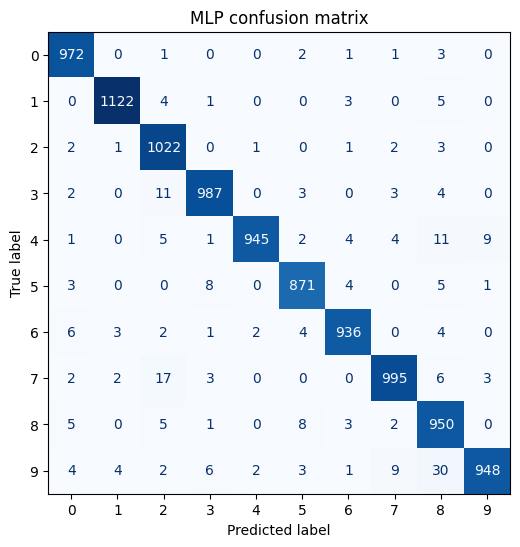

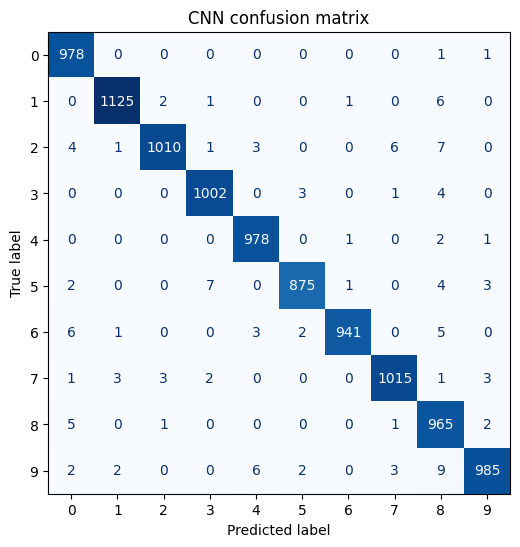

In [54]:
for name, (y_true, y_pred, _) in clean_predictions.items():
    cm = confusion_matrix(y_true.numpy(), y_pred.numpy())

    fig, ax = plt.subplots(figsize=(6, 6))
    ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name} confusion matrix")
    plt.show()

The confusion matrices show that both models classify most digits correctly, since most predictions are on the main diagonal.

However, the MLP makes more mistakes overall than the CNN. Some of the most common errors for the MLP are confusing digit 9 with 8, digit 7 with 2, and digit 4 with 8. The CNN reduces many of these errors and produces a cleaner diagonal, which is consistent with its higher overall accuracy.

As for the CNN, it has more errors than the MLP trying to predict digit 2. 

So as stated before, even though the CNN performs better overall, it is not better for every class.

## 8. Do the models make the same mistakes?

We separate the test images into four groups:

- both models are correct
- only the MLP is wrong
- only the CNN is wrong
- both models are wrong

In [55]:
y_true = clean_predictions["MLP"][0]
mlp_pred = clean_predictions["MLP"][1]
cnn_pred = clean_predictions["CNN"][1]

mlp_wrong = mlp_pred != y_true
cnn_wrong = cnn_pred != y_true

error_both = pd.Series({
    "Both correct": (~mlp_wrong & ~cnn_wrong).sum().item(),
    "Only MLP wrong": (mlp_wrong & ~cnn_wrong).sum().item(),
    "Only CNN wrong": (~mlp_wrong & cnn_wrong).sum().item(),
    "Both wrong": (mlp_wrong & cnn_wrong).sum().item()})

error_both.to_frame("Number of test images")

,Number of test images
Both correct,9690
Only MLP wrong,184
Only CNN wrong,58
Both wrong,68


The two models agree on most test images, since both classify over 9,500 images correctly.

However, the CNN correctly classifies 184 images that the MLP gets wrong, while the MLP correctly classifies 58 images that the CNN gets wrong. This shows that the CNN is stronger overall, but the two models do not make exactly the same mistakes.

There are also 68 images that both models classify incorrectly, so some examples are difficult for both models.

## 9. High-confidence mistakes

Not all errors are equal. A wrong prediction with very high confidence is more concerning because the model is both incorrect and certain about its answer.

For that reason, we observe the mistakes for which each model assigns the highest confidence to an incorrect prediction.

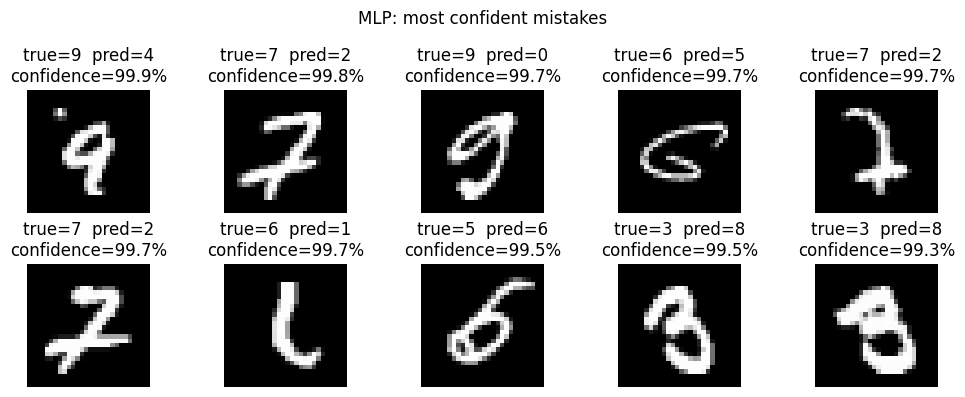

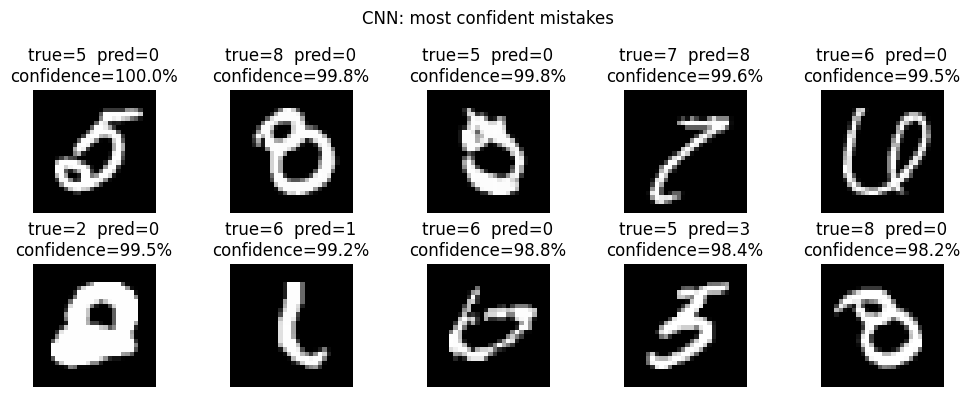

In [56]:
def show_confident_errors(model_name, n=10):
    y_true, y_pred, probabilities = clean_predictions[model_name]
    confidence = probabilities.max(dim=1).values

    wrong_indices = torch.where(y_true != y_pred)[0]
    ordered = wrong_indices[torch.argsort(confidence[wrong_indices], descending=True)]
    selected = ordered[:n]

    fig, axes = plt.subplots(2, 5, figsize=(10, 4))

    for ax, index in zip(axes.flat, selected):
        image, _ = test_data[index.item()]
        image = image * std[0] + mean[0]

        ax.imshow(image.squeeze(), cmap="gray")
        ax.set_title(
            f"true={y_true[index].item()}  pred={y_pred[index].item()}\n"
            f"confidence={confidence[index].item():.1%}")
        ax.axis("off")

    plt.suptitle(f"{model_name}: most confident mistakes")
    plt.tight_layout()
    plt.show()


for name in models:
    show_confident_errors(name)

We can see that both models can be very confident even when their prediction is wrong.

Some of these errors are understandable because several digits are written in an ambiguous way. For example, CNN's 8th most confident mistake could easily be interpreted as a 0, even though its true label is a 6.

However, in other cases the mistake is more obvious. Some digits are clearly different from the predicted class, but the model still has a confidence close to 100%. This is important because it shows that the models are not only making mistakes, but can also be extremely confident when they are wrong.

With this we conclude that confidence should not always be interpreted as a reliable measure of correctness.

## 10. Changing the input

This is the main experiment in the notebook. We create modified versions of the MNIST test images.

We use 3 corruptions:

- **rotation**: the digit is written at an angle
- **translation**: the digit is moved away from the centre
- **Gaussian noise**: random noise is added to the image

This lets us see whether performance depends too much on clean and center digits.

For Gaussian noise, we use the same random noise for both models so that the comparison is fair.

In [57]:
raw_test = datasets.MNIST(root="./data", train=False, download=True, transform=transforms.ToTensor())


class CorruptedMNIST(Dataset):
    def __init__(self, dataset, corruption):
        self.dataset = dataset
        self.corruption = corruption
        self.normalize = transforms.Normalize(mean, std)

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):
        image, label = self.dataset[index]
        image = self.corruption(image.clone(), index)
        image = torch.clamp(image, 0, 1)
        return self.normalize(image), label


def clean(image, index):
    return image


def rotate_20(image, index):
    return TF.rotate(image, 20, interpolation=InterpolationMode.BILINEAR, fill=0)


def shift_4px(image, index):
    return TF.affine(
        image, angle=0, translate=[4, 4], scale=1, shear=[0, 0],
        interpolation=InterpolationMode.BILINEAR, fill=0)


def add_noise(image, index):
    generator = torch.Generator().manual_seed(SEED + index)
    noise = torch.randn(image.shape, generator=generator) * 0.30
    return image + noise


corruptions = {
    "Clean": clean,
    "Rotate 20°": rotate_20,
    "Shift 4 px": shift_4px,
    "Gaussian noise": add_noise}

### What do the corruptions actually look like?

Before evaluating the models, we visualize some images with corruption. This is important because an accuracy value alone does not tell us how severe a transformation is.

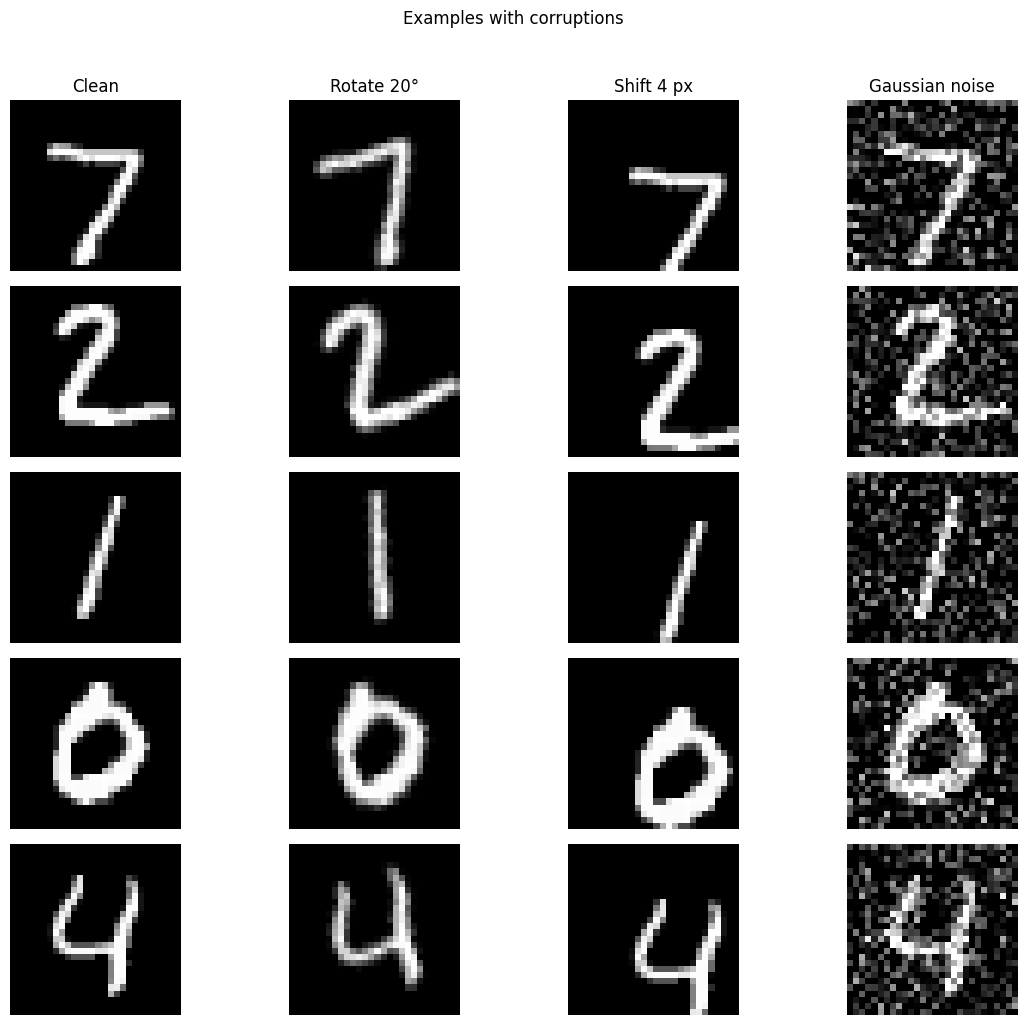

In [58]:
indices = [0, 1, 2, 3, 4]

fig, axes = plt.subplots(
    len(indices),
    len(corruptions),
    figsize=(12, 10))

for row, index in enumerate(indices):
    image, label = raw_test[index]

    for col, (name, corruption) in enumerate(corruptions.items()):
        corrupted = corruption(image.clone(), index)
        corrupted = torch.clamp(corrupted, 0, 1)

        axes[row, col].imshow(corrupted.squeeze(), cmap="gray")
        axes[row, col].axis("off")

        if row == 0:
            axes[row, col].set_title(name)

        if col == 0:
            axes[row, col].set_ylabel(
                f"Label: {label}",
                rotation=0,
                labelpad=30)

plt.suptitle("Examples with corruptions", y=1.02)
plt.tight_layout()
plt.show()

In [59]:
robustness_rows = []

for corruption_name, corruption in corruptions.items():
    corrupted_data = CorruptedMNIST(raw_test, corruption)
    corrupted_loader = DataLoader(corrupted_data, batch_size=BATCH_SIZE)

    for model_name, model in models.items():
        accuracy = evaluate_accuracy(model, corrupted_loader)
        robustness_rows.append({
            "Corruption": corruption_name,
            "Model": model_name,
            "Accuracy": accuracy})

robustness = pd.DataFrame(robustness_rows)
robustness.pivot(index="Corruption", columns="Model", values="Accuracy")

Model,CNN,MLP
Corruption,,
Clean,0.9874,0.9748
Gaussian noise,0.9324,0.9327
Rotate 20°,0.9433,0.9107
Shift 4 px,0.1697,0.0688


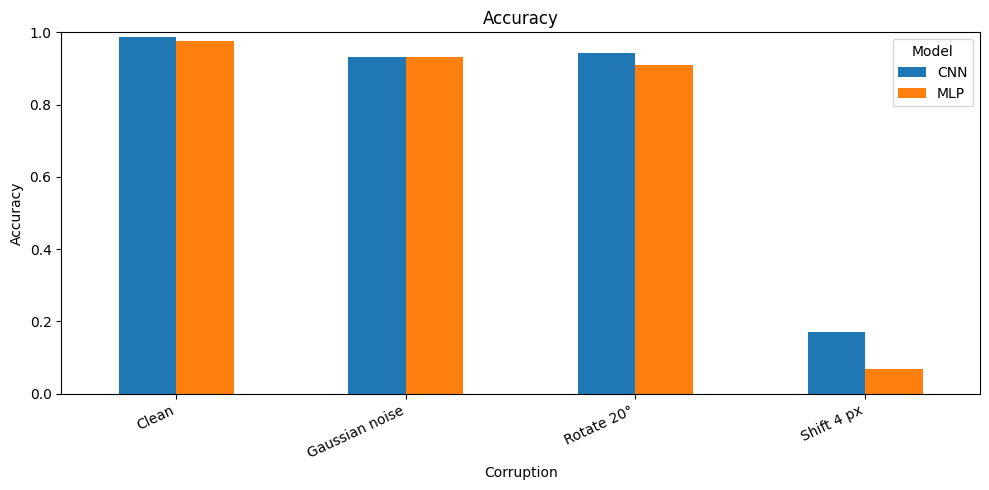

,Corruption,Model,Accuracy,Accuracy drop
5,Shift 4 px,CNN,0.1697,0.8177
7,Gaussian noise,CNN,0.9324,0.0550
3,Rotate 20°,CNN,0.9433,0.0441
1,Clean,CNN,0.9874,0.0000
4,Shift 4 px,MLP,0.0688,0.9060
2,Rotate 20°,MLP,0.9107,0.0641
6,Gaussian noise,MLP,0.9327,0.0421
0,Clean,MLP,0.9748,0.0000


In [60]:
clean_accuracy = (robustness[robustness["Corruption"] == "Clean"].set_index("Model")["Accuracy"])

robustness["Accuracy drop"] = robustness.apply(
    lambda row: clean_accuracy[row["Model"]] - row["Accuracy"], axis=1)

plot_data = robustness.pivot(index="Corruption", columns="Model", values="Accuracy")
plot_data.plot(kind="bar", figsize=(10, 5))
plt.title("Accuracy")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

robustness.sort_values(["Model", "Accuracy drop"], ascending=[True, False])

The **accuracy drop** is very useful here.

The results show that robustness depends on the type of corruption. The CNN is more robust than the MLP to rotation and translation. However, for Gaussian noise, the MLP loses slightly less accuracy than the CNN.

For both models, translating the digits drastically decreases accuracy. Rotation and Gaussian noise produce smaller drops, although they still show high accuracy on the data.

With translation we can see that a slight shift in the images causes a very large decrease in accuracy.

### How quickly does translation hurt performance?

The 4-pixel shift is very severe, so testing only that point can hide how the failure develops. We repeat the experiment with shifts from 0 to 4 pixels and plot the accuracy curve for both models.

Model,CNN,MLP
Shift (pixels),,
0,0.9874,0.9748
1,0.9696,0.9013
2,0.7941,0.5611
3,0.4179,0.2018
4,0.1697,0.0688


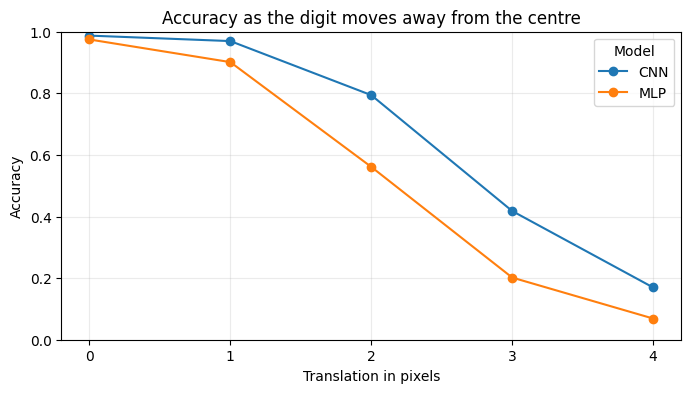

In [61]:
translation_rows = []

for pixels in range(5):
    def shift_image(image, index, pixels=pixels):
        return TF.affine(
            image,
            angle=0,
            translate=[pixels, pixels],
            scale=1,
            shear=[0, 0],
            interpolation=InterpolationMode.BILINEAR,
            fill=0)

    shifted_data = CorruptedMNIST(raw_test, shift_image)
    shifted_loader = DataLoader(shifted_data, batch_size=BATCH_SIZE)

    for model_name, model in models.items():
        translation_rows.append({
            "Shift (pixels)": pixels,
            "Model": model_name,
            "Accuracy": evaluate_accuracy(model, shifted_loader)})

translation_results = pd.DataFrame(translation_rows)
translation_table = translation_results.pivot(
    index="Shift (pixels)",
    columns="Model",
    values="Accuracy")

display(translation_table)

translation_table.plot(marker="o", figsize=(8, 4))
plt.title("Accuracy as the digit moves away from the centre")
plt.xlabel("Translation in pixels")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(range(5))
plt.grid(alpha=0.25)
plt.show()

This curve shows how fast accuracy degrades, specially for the MLP model.

## 11. Can training with corruptions improve robustness?

So far, both models have been trained only on clean MNIST. Now we expose new models to small variations during training.

We do not train with the exact same corruptions used in the robustness test: rotations up to +15º/-15º, translations up to 3 pixels and Gaussian noise with standard deviation 0.15.

In [62]:
augmented_transform = transforms.Compose([
    transforms.RandomApply([
        transforms.RandomRotation(15, interpolation=InterpolationMode.BILINEAR, fill=0)], p=0.3),

    transforms.RandomApply([
        transforms.RandomAffine(degrees=0, translate=(3 / 28, 3 / 28), interpolation=InterpolationMode.BILINEAR, fill=0)], p=0.3),

    transforms.ToTensor(),

    transforms.RandomApply([
        transforms.Lambda(
            lambda x: torch.clamp(x + torch.randn_like(x) * 0.15, 0, 1))], p=0.3),

    transforms.Normalize(mean, std)])

aug_train_data = datasets.MNIST(root="./data", train=True, download=True, transform=augmented_transform)

aug_train_loader = DataLoader(aug_train_data, batch_size=BATCH_SIZE, shuffle=True)

print(f"Augmented training images: {len(aug_train_data):,}")

Augmented training images: 60,000


We can see some examples seen during training.

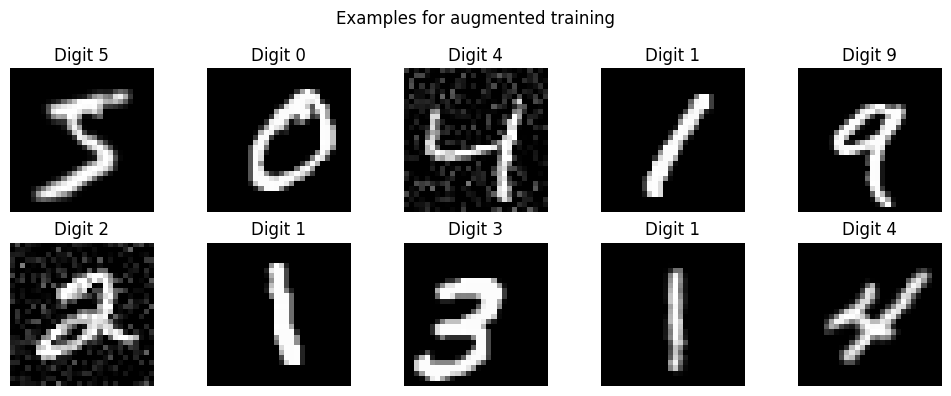

In [63]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for ax, index in zip(axes.flat, range(10)):
    image, label = aug_train_data[index]
    image = image * std[0] + mean[0]  # undo normalization
    image = torch.clamp(image, 0, 1)

    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Digit {label}")
    ax.axis("off")

plt.suptitle("Examples for augmented training")
plt.tight_layout()
plt.show()

In [64]:
augmented_models = {
    "MLP + augmentation": MLP(),
    "CNN + augmentation": CNN()}

augmented_histories = {}

for name, model in augmented_models.items():
    print(f"\nTraining {name}")
    augmented_histories[name] = train_model(model, aug_train_loader, epochs=5)


Training MLP + augmentation
Epoch 1: training loss = 0.5272
Epoch 2: training loss = 0.2139
Epoch 3: training loss = 0.1587
Epoch 4: training loss = 0.1318
Epoch 5: training loss = 0.1219

Training CNN + augmentation
Epoch 1: training loss = 0.3340
Epoch 2: training loss = 0.1126
Epoch 3: training loss = 0.0815
Epoch 4: training loss = 0.0674
Epoch 5: training loss = 0.0556


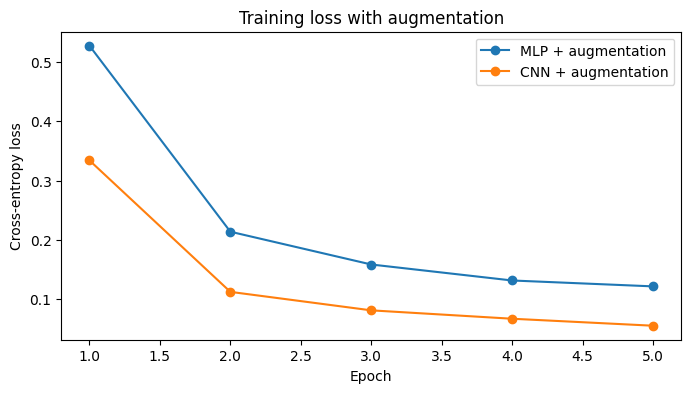

In [65]:
plt.figure(figsize=(8, 4))

for name, history in augmented_histories.items():
    plt.plot(history["epoch"], history["train_loss"], marker="o", label=name)

plt.title("Training loss with augmentation")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.legend()
plt.show()

As it happened with clean data, the CNN model has a lower loss than MLP. Moreover, as the number of epochs increase, the cross-entropy loss decreases. This relationship is not linear, where most loss decreases during the first 2 epochs.

### Clean training vs augmented training

We now evaluate the 4 models on the same clean and corrupted test sets. This lets us check whether augmentation improves robustness.

In [66]:
comparison_models = {
    "MLP clean training": models["MLP"],
    "MLP augmented training": augmented_models["MLP + augmentation"],
    "CNN clean training": models["CNN"],
    "CNN augmented training": augmented_models["CNN + augmentation"]}

comparison_rows = []

for corruption_name, corruption in corruptions.items():
    corrupted_data = CorruptedMNIST(raw_test, corruption)
    corrupted_loader = DataLoader(corrupted_data, batch_size=BATCH_SIZE)

    for model_name, model in comparison_models.items():
        comparison_rows.append({
            "Corruption": corruption_name,
            "Model": model_name,
            "Accuracy": evaluate_accuracy(model, corrupted_loader)})

augmentation_results = pd.DataFrame(comparison_rows)
augmentation_table = augmentation_results.pivot(
    index="Corruption",
    columns="Model",
    values="Accuracy")

augmentation_table

Model,CNN augmented training,CNN clean training,MLP augmented training,MLP clean training
Corruption,,,,
Clean,0.9901,0.9874,0.9782,0.9748
Gaussian noise,0.9746,0.9324,0.9588,0.9327
Rotate 20°,0.9540,0.9433,0.9231,0.9107
Shift 4 px,0.7298,0.1697,0.4943,0.0688


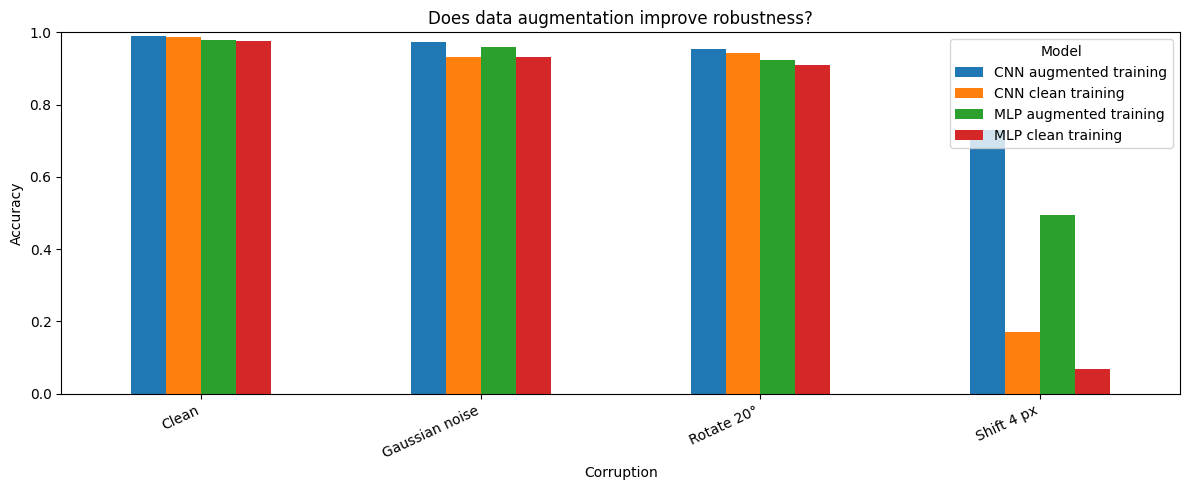

,Corruption,Model,Accuracy,Accuracy drop
0,Clean,CNN augmented training,0.9901,0.0000
1,Clean,CNN clean training,0.9874,0.0000
2,Clean,MLP augmented training,0.9782,0.0000
3,Clean,MLP clean training,0.9748,0.0000
4,Gaussian noise,CNN augmented training,0.9746,0.0155
5,Gaussian noise,CNN clean training,0.9324,0.0550
6,Gaussian noise,MLP augmented training,0.9588,0.0194
7,Gaussian noise,MLP clean training,0.9327,0.0421
8,Rotate 20°,CNN augmented training,0.9540,0.0361
9,Rotate 20°,CNN clean training,0.9433,0.0441


In [67]:
clean_by_model = augmentation_results[augmentation_results["Corruption"] == "Clean"].set_index("Model")["Accuracy"]

augmentation_results["Accuracy drop"] = augmentation_results.apply(
    lambda row: clean_by_model[row["Model"]] - row["Accuracy"], axis=1)

augmentation_table.plot(kind="bar", figsize=(12, 5))
plt.title("Does data augmentation improve robustness?")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

augmentation_results.sort_values(["Corruption", "Model"]).reset_index(drop=True)

We can see that training the model with the corrupted data, not only improves performance on shifted, rotated or noisy digits, it also improves overall accuracy.


The results show that training with data augmentation improves robustness across all corruptions while also slightly increasing clean accuracy. The largest improvement appears under translation: the CNN increases from 17% to 73% accuracy, while the MLP improves from 7% to 49%. 

These results suggest that including variations during training helps the model generalize better.

## 12. Conclusion

This project shows why creating a classifier only on clean data can give an incomplete picture of its performance.

On the original test set, both models achieve high accuracy, although the CNN performs better overall. However, the CNN is not better for every digit, and the two models do not always make the same mistakes. We also observed that both models can make incorrect predictions with very high confidence, showing that confidence alone should not be interpreted as a guaranteed result.

The robustness experiments reveal that rotation and Gaussian noise reduce accuracy moderately, while translation has a much stronger effect. With a 4-pixel shift, accuracy falls from 98.7% to 17% for the CNN and from 97.5% to 6.9% for the MLP. The translation experiment also shows that this degradation happens progressively as the digit moves further away from the position seen during training. These results demonstrate that high test accuracy does not imply robustness to changes.

Training new models with data augmentation improves this behavior. The augmented CNN reaches 73% accuracy under the 4-pixel translation, compared with 17% without augmentation, while the augmented MLP improves from 7% to 49.4%. Both models also become more robust to rotation and Gaussian noise, while their accuracy on clean MNIST slightly increases rather than decreases.